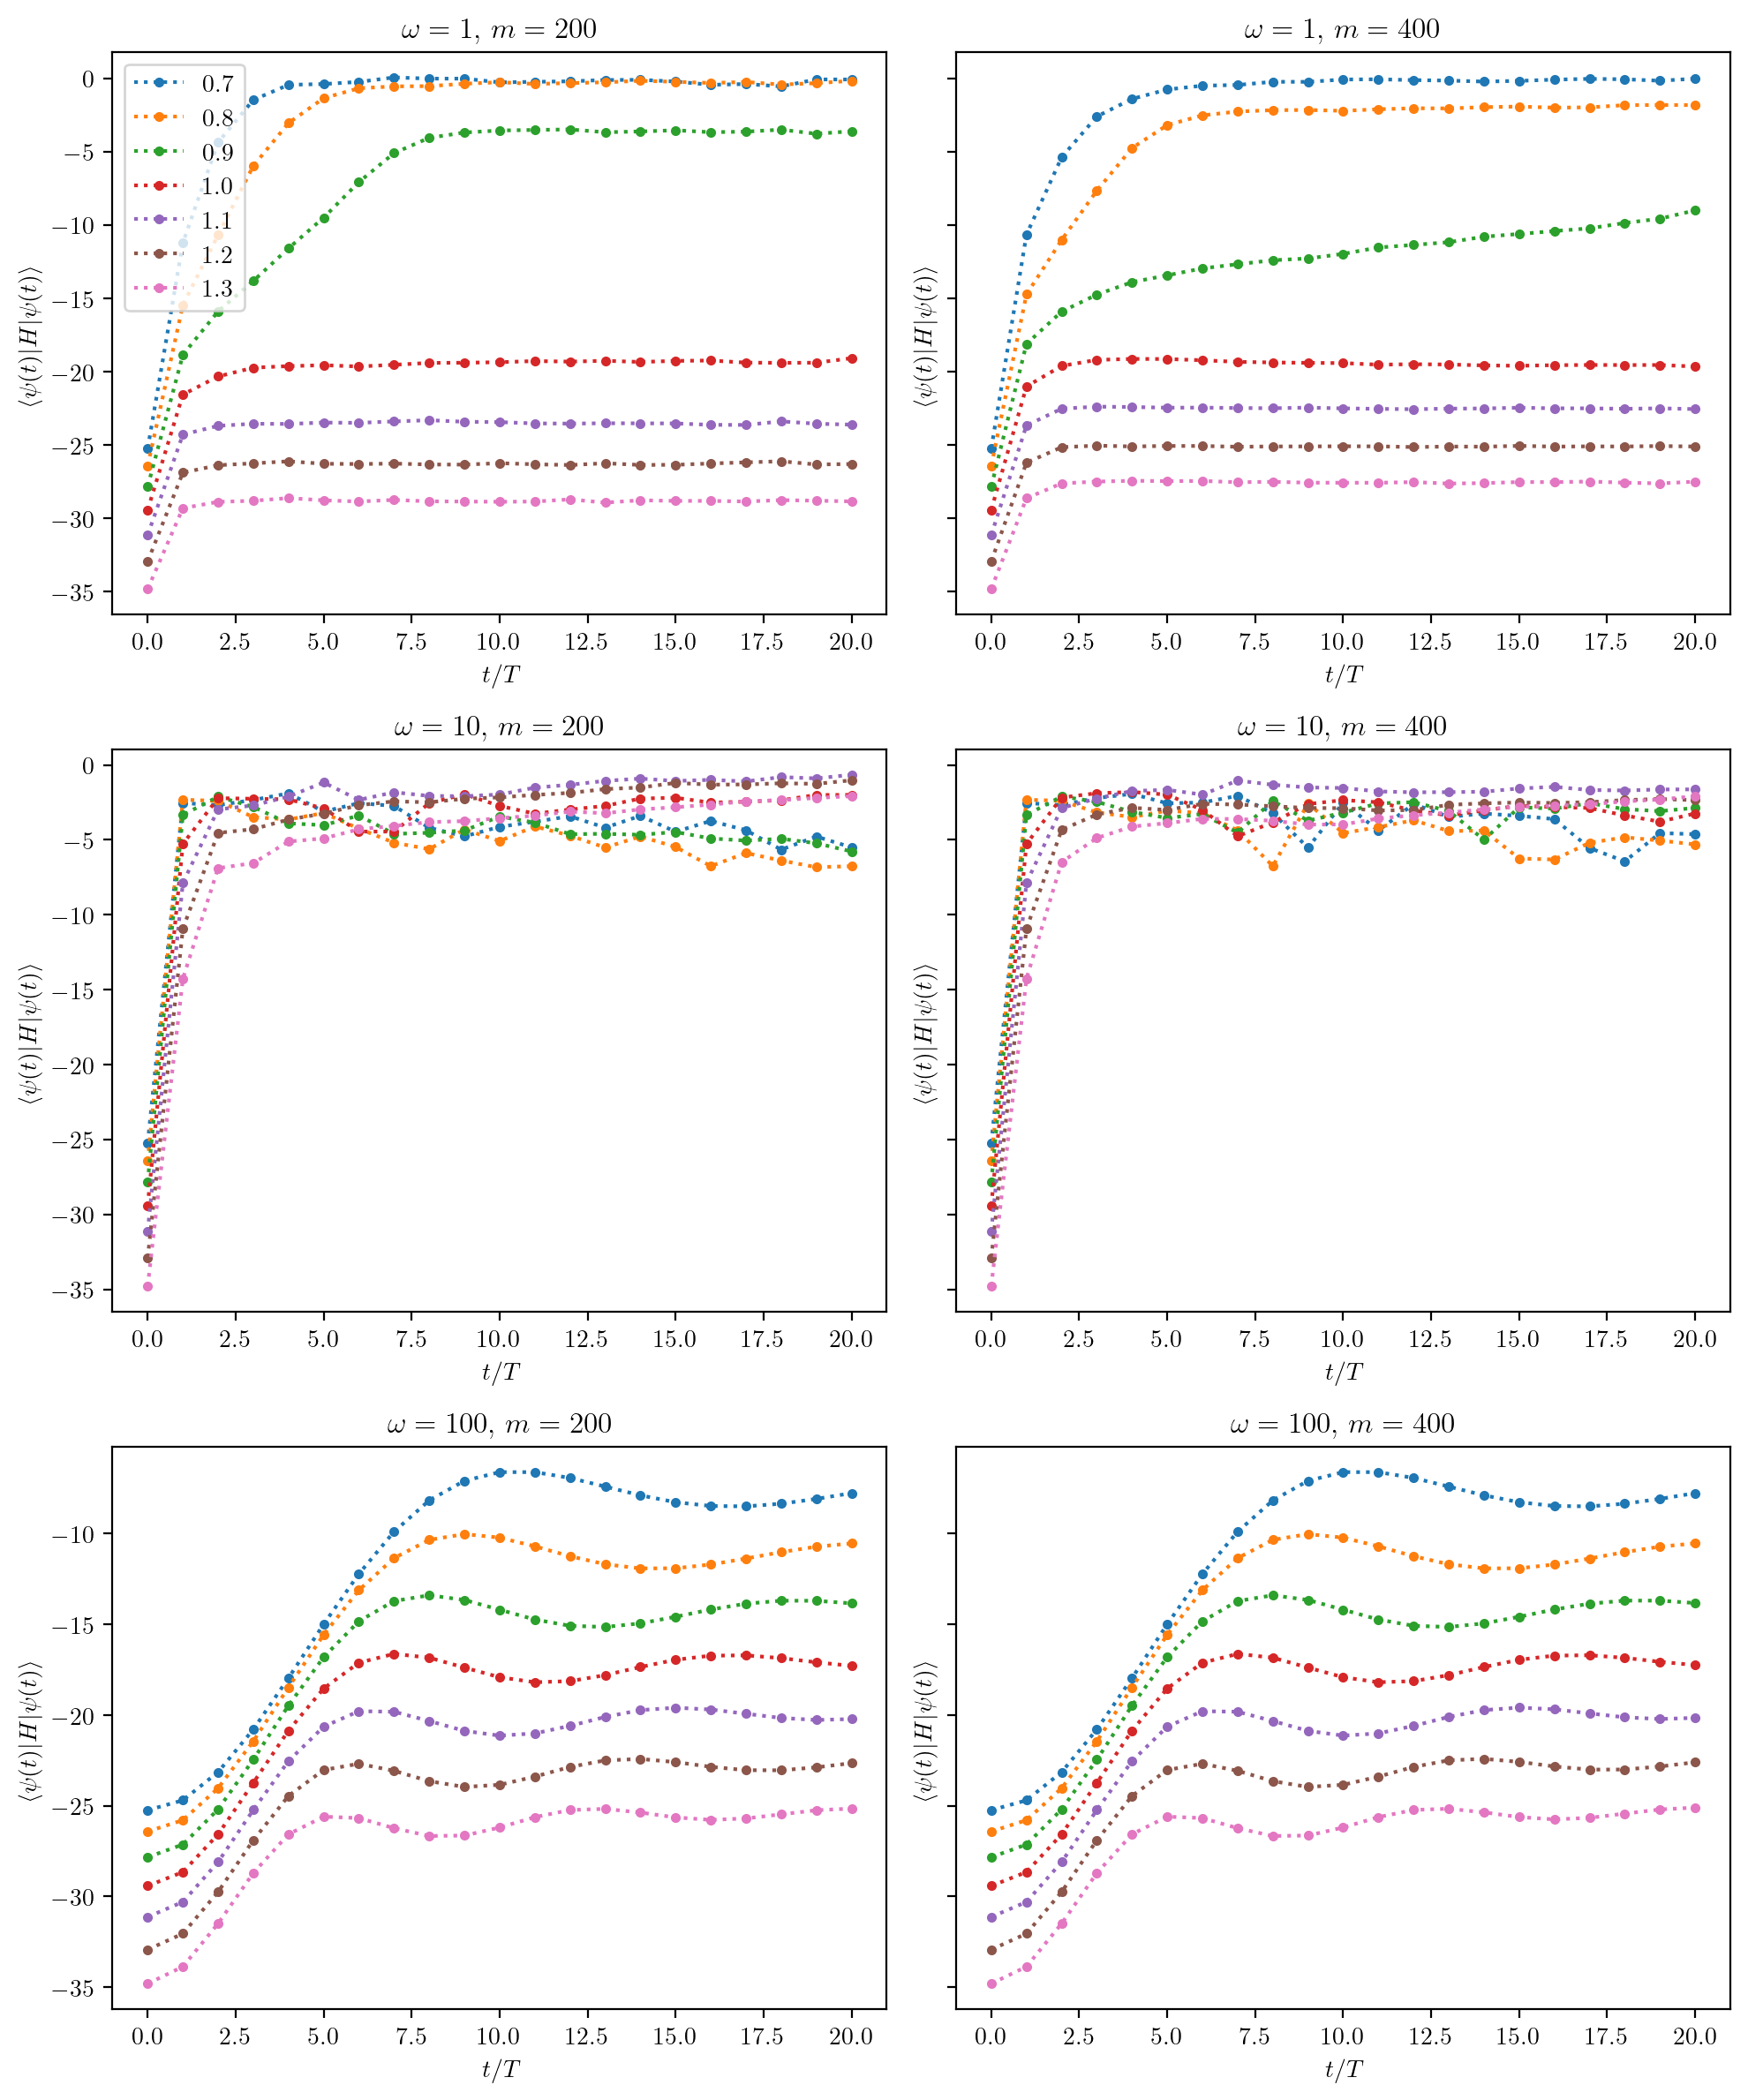

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import h5py

plt.style.use("../majorana.mplstyle")

gs = [0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3]
omegas = [1.0, 10.0, 100.0]
maxdims = [200, 400]
bc = "OBC"

fig, axes = plt.subplots(len(omegas), len(maxdims), figsize=(10, 12), dpi=200, sharey="row")
for i, omega in enumerate(omegas):
    for j, m in enumerate(maxdims):
        for g in gs:
            with h5py.File(f"tebd_batches_2026-05/L24_{bc}_m{m}/om{omega}_g{g}_site1_peven/output.h5", "r") as f:
                sp = f["steps_per_period"][()]
                t = f["times"][()][::sp] * omega / (2 * np.pi)
                E = f["energy_0"][()][::sp]
            axes[i, j].plot(t, E, ".:", label=g)
        axes[i, j].set(title=rf"$\omega = {omega:g}$, $m = {m}$", xlabel=r"$t/T$", ylabel=r"$\langle\psi(t)|H|\psi(t)\rangle$")
axes[0, 0].legend()
fig.tight_layout()
plt.savefig(f"period_energies_{bc}.pdf", bbox_inches="tight")